In [12]:
import math

raw_kc = input("Enter kc: ")
print("Raw input:", raw_kc)
print("Data type of raw input:", type(raw_kc).__name__)

try:
    kc = float(raw_kc)
    print("Data type of converted value:", type(kc).__name__)

    if not math.isfinite(kc):
        print("Error: kc must be a finite number.")
    elif kc <= 0:
        print("Error: kc must be greater than zero.")
    else:
        # Coefficients of kc*x^2 - (3kc + 1)x + 2kc = 0
        a = kc
        b = -(3 * kc + 1)
        c = 2 * kc
        discriminant = b ** 2 - 4 * a * c

        print("a =", a)
        print("b =", b)
        print("c =", c)
        print("Discriminant =", discriminant)

        if discriminant < 0:
            print("Error: The quadratic equation has no real roots.")
        else:
            sqrt_discriminant = math.sqrt(discriminant)
            root1 = (-b + sqrt_discriminant) / (2 * a)
            root2 = (-b - sqrt_discriminant) / (2 * a)

            print("Root 1 =", root1)
            print("Root 2 =", root2)

            physical_roots = [
                root for root in (root1, root2)
                if 0 <= root <= 1
            ]

            if not physical_roots:
                print("Error: No physically meaningful root exists in the range 0 <= x <= 1.")
            else:
                x = min(physical_roots, key=lambda root: abs(root - 0.5))
                print("Physical root, x =", round(x, 6))

                A0 = 2.0
                B0 = 1.0
                C0 = 0.0

                A_eq = A0 - x
                B_eq = B0 - x
                C_eq = C0 + x
                conversion = (x / B0) * 100

                print("Equilibrium [A] = {:.3f} M".format(A_eq))
                print("Equilibrium [B] = {:.3f} M".format(B_eq))
                print("Equilibrium [C] = {:.3f} M".format(C_eq))
                print("Conversion of B = {:.3f}%".format(conversion))

                if conversion >= 70:
                    classification = "HIGH"
                elif conversion >= 40:
                    classification = "MODERATE"
                else:
                    classification = "LOW"

                print("Conversion classification:", classification)

except ValueError:
    print("Error: Please enter a valid number for kc.")

Raw input: 0.5
Data type of raw input: str
Data type of converted value: float
a = 0.5
b = -2.5
c = 1.0
Discriminant = 4.25
Root 1 = 4.561552812808831
Root 2 = 0.4384471871911697
Physical root, x = 0.438447
Equilibrium [A] = 1.562 M
Equilibrium [B] = 0.562 M
Equilibrium [C] = 0.438 M
Conversion of B = 43.845%
Conversion classification: MODERATE


In [ ]:
# Question 2 - Part A -1
# Euler method: C_new = C_old - k * C_old * delta_t

C0 = 1.5       # Initial concentration (mol/L)
k = 0.05       # Rate constant (min^-1)
delta_t = 2    # Time step (min)
total_time = 20

concentration = C0

print("Time (min)\tConcentration (mol/L)\tConversion (%)")
print("----------------------------------------------------------")

for time in range(0, total_time + 1, delta_t):
    conversion = ((C0 - concentration) / C0) * 100
    print(f"{time:<10d}\t{concentration:<22.4f}\t{conversion:<14.2f}")

    if time < total_time:
        concentration = concentration - k * concentration * delta_t

Time (min)	Concentration (mol/L)	Conversion (%)
----------------------------------------------------------
0         	1.5000                	0.00          
2         	1.3500                	10.00         
4         	1.2150                	19.00         
6         	1.0935                	27.10         
8         	0.9842                	34.39         
10        	0.8857                	40.95         
12        	0.7972                	46.86         
14        	0.7174                	52.17         
16        	0.6457                	56.95         
18        	0.5811                	61.26         
20        	0.5230                	65.13         


In [8]:
import math

# Parameters used in the Euler simulation
C0 = 1.5
k = 0.05
delta_t = 2
total_time = 20

# Reproduce the Euler result at 20 minutes
C_euler = C0
for time in range(0, total_time, delta_t):
    C_euler = C_euler - k * C_euler * delta_t

# Exact first-order solution: C(t) = C0 * e^(-k*t)
C_exact = C0 * math.exp(-k * total_time)

# Absolute difference between Euler and exact values
absolute_error = abs(C_euler - C_exact)

print("Euler result at 20 min = {:.6f} mol/L".format(C_euler))
print("Exact result at 20 min = {:.6f} mol/L".format(C_exact))
print("Absolute error = {:.6f} mol/L".format(absolute_error))

Euler result at 20 min = 0.523018 mol/L
Exact result at 20 min = 0.551819 mol/L
Absolute error = 0.028802 mol/L


In [9]:
# Question 2 - Part A -3
# Continue Euler simulation until 50% conversion or 100 minutes

C0 = 1.5
k = 0.05
delta_t = 2
maximum_time = 100

time = 0
concentration = C0
conversion = 0.0

while conversion < 50 and time < maximum_time:
    concentration = concentration - k * concentration * delta_t
    time = time + delta_t
    conversion = ((C0 - concentration) / C0) * 100

if conversion >= 50:
    print("50% conversion reached at {:.0f} min".format(time))
else:
    print("Maximum simulation time of {:.0f} min reached".format(maximum_time))

print("Final concentration = {:.6f} mol/L".format(concentration))
print("Final conversion = {:.2f}%".format(conversion))

50% conversion reached at 14 min
Final concentration = 0.717445 mol/L
Final conversion = 52.17%


In [10]:
# Question 2 - Part b -1
# Count and sum the digits in reactor tags

def check_tag(tag):
    if tag == "":
        print("Error: The tag is empty.")
        return

    digit_count = 0
    digit_sum = 0

    for character in tag:
        if character.isdigit():
            digit_count = digit_count + 1
            digit_sum = digit_sum + int(character)

    if digit_count == 0:
        print("Message: The tag contains no digits.")
    else:
        print("Number of digits:", digit_count)
        print("Sum of digits:", digit_sum)


# Test cases
print("Tag: REACTOR -07/B2026")
check_tag("REACTOR -07/B2026")

print("\nTag: Empty string")
check_tag("")

print("\nTag: ABCDEF")
check_tag("ABCDEF")

Tag: REACTOR -07/B2026
Number of digits: 6
Sum of digits: 17

Tag: Empty string
Error: The tag is empty.

Tag: ABCDEF
Message: The tag contains no digits.


In [11]:
# Question 3 - Part A
# Recursive factorial and combinations

def factorial(n):
    if n < 0:
        return None
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0:
        print("Error: n and r must be non-negative.")
        return None

    if r > n:
        print("Error: r cannot be greater than n.")
        return None

    result = factorial(n) // (factorial(r) * factorial(n - r))
    return result


# Test cases
print("Number of catalyst sets for n = 7, r = 2:", combination(7, 2))
print("Test for n = 4, r = 6:")
combination(4, 6)

Number of catalyst sets for n = 7, r = 2: 21
Test for n = 4, r = 6:
Error: r cannot be greater than n.


In [14]:
# Question 3 - Part B: Distillation sampling times

def fib_iter(n):
    numbers = []
    a, b = 0, 1

    for _ in range(n):
        numbers.append(a)
        a, b = b, a + b

    return numbers


def fib_rec(k):
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


def fib_iter_k(k):
    if k < 0:
        raise ValueError("k must be non-negative.")

    a, b = 0, 1
    for _ in range(k):
        a, b = b, a + b
    return a


n = 9
fibonacci_numbers = fib_iter(n)

print("Recursive and iterative results agree:")
for k in range(n):
    if fib_rec(k) != fib_iter_k(k):
        print("Mismatch at k =", k)
        break
else:
    print("Yes, both functions agree for k = 0 to", n - 1)

print("\nSample No. | Fibonacci tag | Sampling time (min)")
print("-----------------------------------------------")

for sample_no, value in enumerate(fibonacci_numbers, start=1):
    print(f"{sample_no:^10} | {value:^14} | {value * 5:^20}")

Recursive and iterative results agree:
Yes, both functions agree for k = 0 to 8

Sample No. | Fibonacci tag | Sampling time (min)
-----------------------------------------------
    1      |       0        |          0          
    2      |       1        |          5          
    3      |       1        |          5          
    4      |       2        |          10         
    5      |       3        |          15         
    6      |       5        |          25         
    7      |       8        |          40         
    8      |       13       |          65         
    9      |       21       |         105         


In [15]:
# Question 4 - Part A
# Hydrogen peroxide concentration at two catalyst loadings

import pandas as pd

kinetics_data = {
    "time_min": [0, 10, 20, 30, 40, 50],
    "run1_low_loading_mol_L": [1.20, 0.98, 0.80, 0.66, 0.54, 0.44],
    "run2_high_loading_mol_L": [1.20, 0.80, 0.54, 0.36, 0.24, 0.16]
}

df = pd.DataFrame(kinetics_data)
print("Original DataFrame:")
print(df)

# Save without the pandas DataFrame index
df.to_csv("kinetics.csv", index=False)
df.to_json("kinetics.json", orient="records", indent=4)

# Read the CSV back
csv_df = pd.read_csv("kinetics.csv")

print("\nShape of CSV DataFrame:", csv_df.shape)
print("Data types:")
print(csv_df.dtypes)

Original DataFrame:
   time_min  run1_low_loading_mol_L  run2_high_loading_mol_L
0         0                    1.20                     1.20
1        10                    0.98                     0.80
2        20                    0.80                     0.54
3        30                    0.66                     0.36
4        40                    0.54                     0.24
5        50                    0.44                     0.16

Shape of CSV DataFrame: (6, 3)
Data types:
time_min                     int64
run1_low_loading_mol_L     float64
run2_high_loading_mol_L    float64
dtype: object


In [ ]:
# que 4 part b
# Mean and standard deviation for both catalyst-loading runs

import pandas as pd

# Use the saved kinetics data
kinetics_df = pd.read_csv("kinetics.csv")

mean_run1 = kinetics_df["run1_low_loading_mol_L"].mean()
std_run1 = kinetics_df["run1_low_loading_mol_L"].std()

mean_run2 = kinetics_df["run2_high_loading_mol_L"].mean()
std_run2 = kinetics_df["run2_high_loading_mol_L"].std()

print("Run 1 mean = {:.3f} mol/L".format(mean_run1))
print("Run 1 standard deviation = {:.3f} mol/L".format(std_run1))
print("Run 2 mean = {:.3f} mol/L".format(mean_run2))
print("Run 2 standard deviation = {:.3f} mol/L".format(std_run2))

if std_run1 > std_run2:
    print("Run 1 shows more variation.")
elif std_run2 > std_run1:
    print("Run 2 shows more variation.")
else:
    print("Both runs show the same variation.")

Run 1 mean = 0.770 mol/L
Run 1 standard deviation = 0.284 mol/L
Run 2 mean = 0.550 mol/L
Run 2 standard deviation = 0.392 mol/L
Run 2 shows more variation.


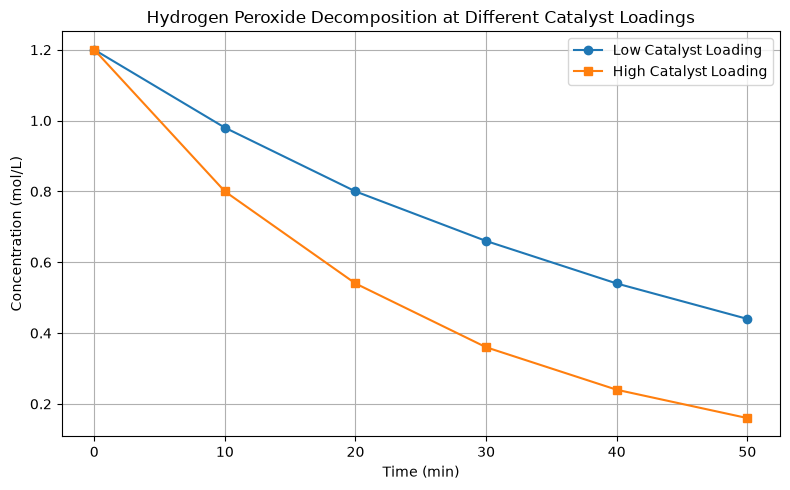

In [17]:
# Question 4 - Part C
# Plot both catalyst-loading runs

import pandas as pd
import matplotlib.pyplot as plt

# Read the saved kinetics data
kinetics_df = pd.read_csv("kinetics.csv")

plt.figure(figsize=(8, 5))
plt.plot(
    kinetics_df["time_min"],
    kinetics_df["run1_low_loading_mol_L"],
    marker="o",
    label="Low Catalyst Loading"
)
plt.plot(
    kinetics_df["time_min"],
    kinetics_df["run2_high_loading_mol_L"],
    marker="s",
    label="High Catalyst Loading"
)

plt.title("Hydrogen Peroxide Decomposition at Different Catalyst Loadings")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

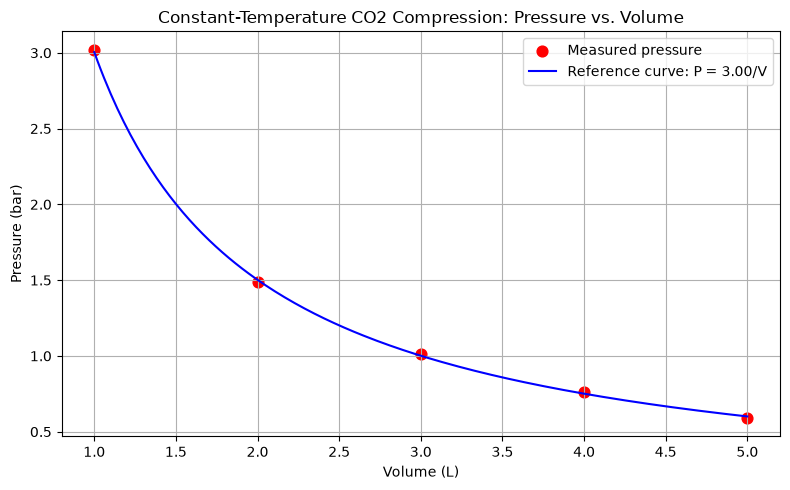

Calculated k = 3.004 bar·L


In [18]:
# Question 4 - Part D
# Pressure-volume relationship for CO2 in a piston-cylinder

import numpy as np
import matplotlib.pyplot as plt

volume = np.array([1, 2, 3, 4, 5], dtype=float)       # L
pressure = np.array([3.02, 1.49, 1.01, 0.76, 0.59])   # bar

# Boyle's-law constant: mean of each measured P*V value
k = np.mean(pressure * volume)

# Reference curve over a smooth volume range
reference_volume = np.linspace(volume.min(), volume.max(), 200)
reference_pressure = k / reference_volume

plt.figure(figsize=(8, 5))
plt.scatter(volume, pressure, color="red", marker="o", s=60,
            label="Measured pressure")
plt.plot(reference_volume, reference_pressure, color="blue",
         label=f"Reference curve: P = {k:.2f}/V")

plt.title("Constant-Temperature CO2 Compression: Pressure vs. Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Calculated k = {k:.3f} bar·L")